# K-Medoids

- Una variación de k-means
- Cambiamos de prototipo

-------

# Usar instancia real como prototipo

- En **k-medoids** el prototipo debe ser un punto (instancia) observado
- Se optimizan intercambios
- Se busca reducir un criterio de error absoluto:
    - Nota: Se puede usar otra métrica distinta

$$
J_{medoid} = \sum_{k=1}^{K} \sum_{x^{(i)} \in C_k} \lVert x^{(i)} - c_k \rVert _1
$$

- El medoid no puede desplazarse hacia una posición inexistente: siempre es una de las instancias

---------

## Algoritmo

1. Seleccionar K objetos representativos **$m_k$**
2. Asignar cada $x^{(i)}$ al medoid más cercano.
3. Elegir una instancia no representativa $x^{(j)}$
4. Evaluar el cambio de costo al intercambiar $m_k \Leftrightarrow x^{(j)}$
5. Si el costo disminuye, aceptar el intercambio.
6. Repetir hasta convergencia.

-------

## Diferencias con k-means

| K-Medoids | K-Means |
|---|---|
| Mayor costo computacional | Menor costo computacional | 
| Usa una instancia real del conjunto de datos | Usa el promedio de los puntos | 
| Puede utilizar distintas métricas de distancia | Generalmente usa distancia euclídea | 
| Más robusto frente a ruido y valores atípicos | Simple, rápido y eficiente con grandes conjuntos de datos | 
| Más lento y costoso; depende de la selección de medoids | Sensible a outliers y requiere variables numéricas | 

-----

# En código

- KMedoids no viene de sklearn.cluster: se instala desde scikit-learn-extra

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from sklearn_extra.cluster import KMedoids # pip install scikit-learn-extra

plt.style.use('dark_background') # poner modo oscuro los plots

RAND_STATE = 42 # para reproducibilidad, se usará 42 como random state
K = 3   

------

### 1. Cargar Iris y elegir dos variables para poder graficarlas

In [26]:
iris = load_iris(as_frame=True)
columnas = ["sepal length (cm)", "sepal width (cm)"]
X = iris.data[columnas].copy()

X

,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6
...,...,...
145,6.7,3.0
146,6.3,2.5
147,6.5,3.0
148,6.2,3.4


-----

### 2. Escalar y graficar los datos


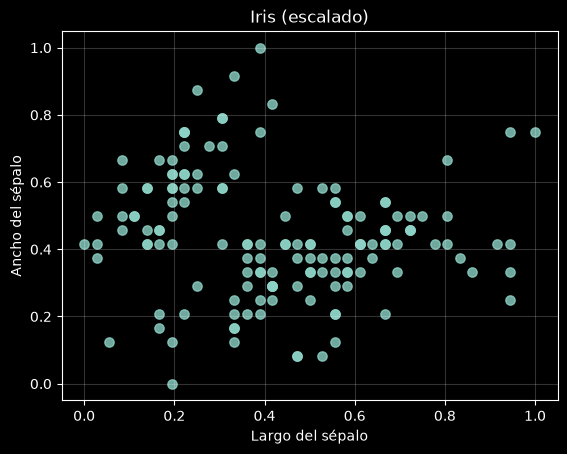

In [27]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X) # El modelo y las predicciones deben usar el mismo scaler ya ajustado.

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], s=45, alpha=0.8)
plt.xlabel("Largo del sépalo")
plt.ylabel("Ancho del sépalo")
plt.title("Iris (escalado)")
plt.grid(alpha=0.2)


----

### 3. Ajustar el modelo

##### **method**:
- Método de optimización de los medoides.
    - *pam*: busca mejorar la selección de medoides
##### **init**: 
- Estrategia para elegir los medoides iniciales
    - *k-medoids++*: intenta elegir puntos iniciales separados entre sí.


In [28]:
# 4. Ajustar K-Medoids
modelo = KMedoids(
    n_clusters=K,
    metric="euclidean",
    method="pam",
    init="k-medoids++",
    random_state=RAND_STATE
)
modelo.fit(X_scaled)

/home/ldan/miniconda3/envs/ml_env/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/home/ldan/miniconda3/envs/ml_env/lib/python3.13/site-packages/sklearn_extra/cluster/_k_medoids.py:297: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


,n_clusters,3
,method,'pam'
,init,'k-medoids++'
,random_state,42
,metric,'euclidean'
,max_iter,300
Name,Type,Value
cluster_centers_,"ndarray[float64](3, 2)","[[0.67,0.46], [0.42,0.29], [0.19,0.58]]"
inertia_,float64,20.86
labels_,"ndarray[int64](150,)","[2,2,2,...,0,0,1]"
medoid_indices_,"ndarray[int64](3,)","[65,82, 7]"


-----

### 4. Visualizando los clusters

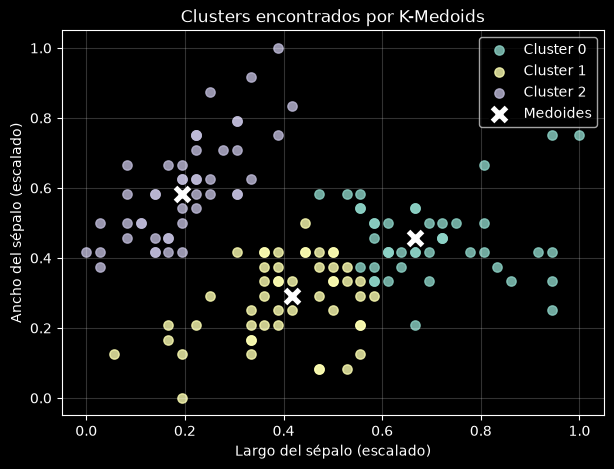

In [30]:
etiquetas = modelo.labels_

# 5. Graficar los clusters y destacar los medoides
plt.figure(figsize=(7, 5))

for cluster in range(K):
    mask = etiquetas == cluster
    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        s=45,
        alpha=0.8,
        label=f"Cluster {cluster}"
    )

# Los centros de K-Medoids son observaciones del dataset original
medoides_scaled = modelo.cluster_centers_
plt.scatter(
    medoides_scaled[:, 0],
    medoides_scaled[:, 1],
    marker="X",
    s=220,
    c="white",
    edgecolors="black",
    linewidths=1.5,
    label="Medoides"
)

plt.xlabel("Largo del sépalo (escalado)")
plt.ylabel("Ancho del sépalo (escalado)")
plt.title("Clusters encontrados por K-Medoids")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

--------

### 5. Consultar los medoides en las unidades originales

In [31]:
medoides_originales = scaler.inverse_transform(medoides_scaled)
tabla_medoides = pd.DataFrame(medoides_originales, columns=columnas)
tabla_medoides.index.name = "cluster"

print("Medoides (valores originales):")
print(tabla_medoides)

print("\nÍndices de las filas que son medoides:")
print(modelo.medoid_indices_)

print(f"\nInercia: {modelo.inertia_:.4f}")

Medoides (valores originales):
         sepal length (cm)  sepal width (cm)
cluster                                     
0                      6.7               3.1
1                      5.8               2.7
2                      5.0               3.4

Índices de las filas que son medoides:
[65 82  7]

Inercia: 20.8565


---------

### 6. Predecir el cluster de observaciones nuevas
Cada fila debe contener, en este orden:


[largo del sépalo, ancho del sépalo]

In [32]:
nuevos = pd.DataFrame(
    [
        [5.1, 3.5],
        [6.7, 3.0],
        [5.8, 2.7],
    ],
    columns=columnas
)

nuevos_scaled = scaler.transform(nuevos)
clusters_nuevos = modelo.predict(nuevos_scaled)

-------

In [33]:
resultado = nuevos.copy()
resultado["cluster"] = clusters_nuevos
print("\nPredicciones para los datos nuevos:")
print(resultado)


Predicciones para los datos nuevos:
   sepal length (cm)  sepal width (cm)  cluster
0                5.1               3.5        2
1                6.7               3.0        0
2                5.8               2.7        1


------

### 7. Graficar los datos originales agrupados y los nuevos puntos

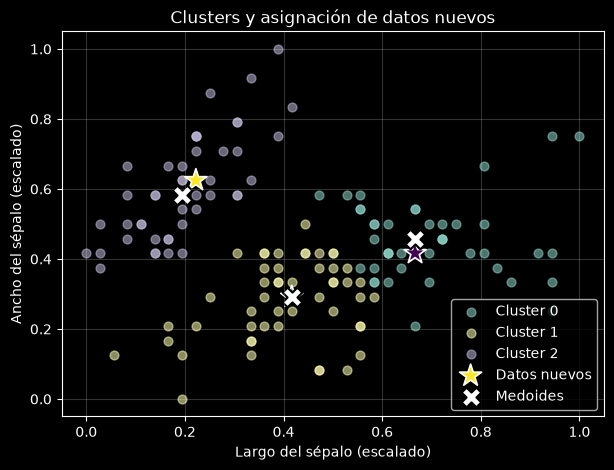

In [ ]:
plt.figure(figsize=(7, 5))

for cluster in range(K):
    mask = etiquetas == cluster
    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        s=40,
        alpha=0.55,
        label=f"Cluster {cluster}"
    )

# Nuevos puntos, coloreados según predict()
plt.scatter(
    nuevos_scaled[:, 0],
    nuevos_scaled[:, 1],
    c=clusters_nuevos,
    cmap="viridis",
    marker="*",
    s=280,
    edgecolors="white",
    linewidths=1.2,
    label="Datos nuevos"
)

# Medoides
plt.scatter(
    medoides_scaled[:, 0],
    medoides_scaled[:, 1],
    marker="X",
    s=200,
    c="white",
    edgecolors="black",
    linewidths=1.5,
    label="Medoides"
)

plt.xlabel("Largo del sépalo (escalado)")
plt.ylabel("Ancho del sépalo (escalado)")
plt.title("Clusters y asignación de datos nuevos")
plt.legend()
plt.grid(alpha=0.2)
plt.show()